# 03 · Restatements, look-ahead bias and data quality

Three questions a user of this data would ask before trusting it:

1. **How late are the numbers?** (reporting lag)
2. **How often, and by how much, do they change after first publication?**
3. **How much would a backtest be wrong if it ignored transaction time?**

then a data-quality monitor over the lot.

In [1]:
import datetime as dt
import pandas as pd
import matplotlib.pyplot as plt
from edgar_bitemporal.db import q, SQL_DIR

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1 · Reporting lag

Days between the end of a fiscal year and the first filing that reported its net income. This is how long a "point-in-time" feature must wait before it is allowed to exist.

Periods that first appear as comparatives in a much later filing (history from before XBRL filing began, see notebook 01 section 7) are excluded: their first-seen date is not the original publication date.

In [2]:
lag = q('''
    select c.entity_name, s.period_end, (s.first_filed - s.period_end) as lag_days
    from fact_first_seen s join company c using (cik)
    where s.tag = 'NetIncomeLoss' and s.period_start is not null
      and s.period_end - s.period_start between 350 and 380
''')
lag["lag_days"] = lag.lag_days.astype(int)
LAG_CUTOFF = 150                      # annual reports are due within ~60-90 days
all_periods = len(lag)
lag = lag[lag.lag_days <= LAG_CUTOFF]
print(f"{len(lag)} annual periods kept, {all_periods - len(lag)} excluded as late-appearing comparatives")
lag.groupby("entity_name").lag_days.describe()[["count", "min", "50%", "max"]]

17 annual periods kept, 2 excluded as late-appearing comparatives


,count,min,50%,max
entity_name,,,,
THE BOEING COMPANY,17.0,27.0,39.0,45.0


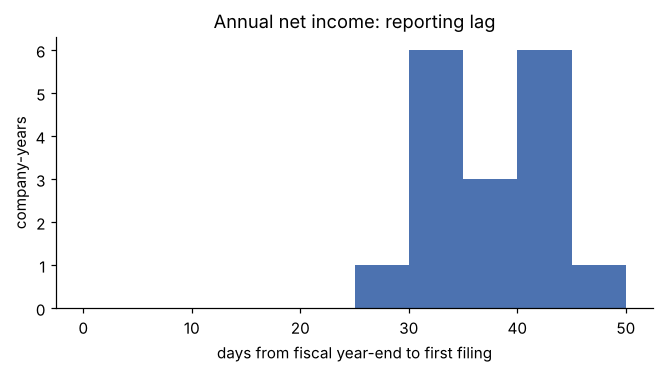

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(lag.lag_days, bins=range(0, int(lag.lag_days.max()) + 10, 5), color="#4C72B0")
ax.set_xlabel("days from fiscal year-end to first filing"); ax.set_ylabel("company-years")
ax.set_title("Annual net income: reporting lag"); plt.show()

## 2 · How often are numbers restated, and by how much?

In [4]:
# "restated" = the value ever differed between filings (includes the pure sign flips counted below)
by_tag = q('''
    select tag,
           count(*)                                          as periods,
           count(*) filter (where n_distinct_values > 1)     as restated,
           round(100.0 * count(*) filter (where n_distinct_values > 1) / count(*), 1) as pct_restated
    from fact_first_seen
    group by tag order by pct_restated desc
''')
by_tag

,tag,periods,restated,pct_restated
0,CostOfRevenue,124,30,24.2
1,GrossProfit,112,21,18.8
2,OperatingIncomeLoss,124,23,18.5
3,NetCashProvidedByUsedInOperatingActivities,75,6,8.0
4,EarningsPerShareDiluted,124,8,6.5
5,NetIncomeLoss,124,8,6.5
6,Revenues,124,8,6.5
7,ResearchAndDevelopmentExpense,112,5,4.5
8,Assets,70,2,2.9
9,StockholdersEquity,70,1,1.4


In [5]:
mag = q("select abs(pct_change)::float as m from fact_revisions where pct_change is not null and value <> -prev_value")["m"]
print(f"{len(mag):,} revisions with a new magnitude; relative size of the change:")
mag.describe(percentiles=[.5, .9, .99]).rename("abs % change").to_frame().T

105 revisions with a new magnitude; relative size of the change:


,count,mean,std,min,50%,90%,99%,max
abs % change,105.0,0.052699,0.35712,0.00015,0.006814,0.047232,0.212996,3.664789


A revision where the new value is exactly the negative of the old one (`-x` becomes `+x`) carries no new information: only the sign convention changed, and it would show up as a relative change of 200%. The table above leaves those out; here they are, counted separately:

In [6]:
q('''
    select tag, count(*) as pure_sign_flips
    from fact_revisions where value = -prev_value
    group by tag order by pure_sign_flips desc
''')

,tag,pure_sign_flips
0,CostOfRevenue,10


A model that treats every revision as new information would count these as events. They are worth filtering before measuring how often companies restate.

## 3 · What does ignoring transaction time cost?

A backtest asks, on date D: *what was this company's most recent annual net income?* Two ways to answer:

* **valid-time only:** every annual period that had ended by D, with the latest value ever recorded (what a naive join gives you)
* **as-of:** `facts_as_of(D)`, what was actually public on D

For each January 31 (just after a December year-end, before most 10-Ks), count the periods the naive query leaks:

In [7]:
LEAK_SQL = '''
with annual as (
    select f.* from fact f
    join fact_first_seen s using (cik, taxonomy, tag, unit, period_start, period_end)
    where f.tag = 'NetIncomeLoss' and f.period_start is not null
      and f.period_end - f.period_start between 350 and 380
      and s.first_filed - s.period_end <= %(cutoff)s    -- skip pre-XBRL history (see notebook 01 s.7)
),
naive as (                              -- valid time only: periods ended by D, latest value ever
    select distinct on (cik, unit, period_start, period_end)
           cik, unit, period_start, period_end, value, filed
    from annual
    where period_end <= %(d)s
    order by cik, unit, period_start, period_end, filed desc, accn desc
),
known as (                              -- what was public on D
    select cik, unit, period_start, period_end, value, filed
    from facts_as_of(%(d)s) a
    where a.tag = 'NetIncomeLoss'
      and exists (select 1 from annual x
                  where x.cik = a.cik and x.unit = a.unit and x.period_start = a.period_start
                    and x.period_end = a.period_end)
      and a.period_end <= %(d)s
)
select %(d)s::date                                                        as backtest_date,
       count(*)                                                           as periods_in_naive,
       count(*) filter (where k.cik is null)                              as not_yet_filed,
       count(*) filter (where k.cik is not null and k.value <> n.value)   as value_since_restated
from naive n
left join known k using (cik, unit, period_start, period_end)
'''
first_year = int(q("select extract(year from min(filed))::int as y from fact").y[0]) + 1
leak = pd.concat([q(LEAK_SQL, {"d": dt.date(y, 1, 31), "cutoff": LAG_CUTOFF})
                  for y in range(first_year, dt.date.today().year + 1)], ignore_index=True)
leak = leak[leak.periods_in_naive > 0].reset_index(drop=True)
leak["pct_leaked"] = (100 * (leak.not_yet_filed + leak.value_since_restated) / leak.periods_in_naive).round(1)
leak

,backtest_date,periods_in_naive,not_yet_filed,value_since_restated,pct_leaked
0,2010-01-31,1,1,0,100.0
1,2011-01-31,2,1,0,50.0
2,2012-01-31,3,1,0,33.3
3,2013-01-31,4,1,0,25.0
4,2014-01-31,5,1,0,20.0
5,2015-01-31,6,1,0,16.7
6,2016-01-31,7,1,0,14.3
7,2017-01-31,8,1,0,12.5
8,2018-01-31,9,1,1,22.2
9,2019-01-31,10,1,2,30.0


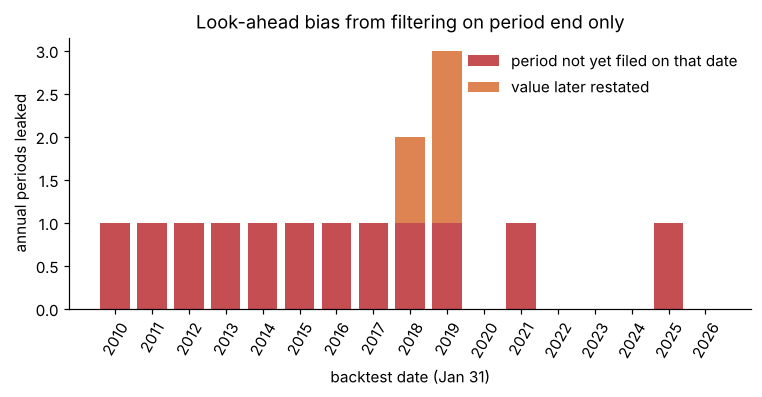

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
x = leak.backtest_date.astype(str).str[:4]
ax.bar(x, leak.not_yet_filed, label="period not yet filed on that date", color="#C44E52")
ax.bar(x, leak.value_since_restated, bottom=leak.not_yet_filed, label="value later restated", color="#DD8452")
ax.set_ylabel("annual periods leaked"); ax.set_xlabel("backtest date (Jan 31)")
ax.set_title("Look-ahead bias from filtering on period end only")
ax.legend(frameon=False); plt.xticks(rotation=60); plt.show()

Each leaked period is information a trader on that date could not have had. Read the table above for how often that happens on your data.

## 4 · Data-quality monitor

`sql/checks.sql` is one query, one row per check. These are monitored rather than enforced, so a violation shows up here instead of aborting the load.

In [9]:
q((SQL_DIR / "checks.sql").read_text())

,check_name,violations,meaning
0,filed_before_period_end,0,filing date is earlier than the period it reports
1,future_filed,0,filing date in the future
2,implausible_duration,0,duration fact spanning more than 400 days
3,instant_with_start,0,start date present on a balance-sheet style ta...
4,inverted_period,0,period_start is after period_end


Only the core tags are loaded into Postgres, so this complements the raw-file scan in notebook 01 (section 6), which covers every tag and found rows filed before their period ended. To run the monitor over everything: `python -m edgar_bitemporal.load --all-tags`.

## Summary

In [10]:
s = q('''
    select count(*) as periods,
           count(*) filter (where n_reports > 1)          as reported_again,
           count(*) filter (where n_distinct_values > 1)  as restated
    from fact_first_seen
''').iloc[0]
r = q("select count(*) as n from fact_revisions where value = -prev_value").iloc[0]
print(f"{int(s.periods):,} company-periods loaded")
print(f"{int(s.reported_again):,} ({s.reported_again / s.periods:.1%}) were reported in more than one filing")
print(f"{int(s.restated):,} ({s.restated / s.periods:.1%}) were reported with more than one value")
print(f"{int(r.n):,} of the revisions only flip the sign (same magnitude)")
print(f"lag to first annual filing: median {lag.lag_days.median():.0f} days, max {lag.lag_days.max()} days (periods first reported within {LAG_CUTOFF} days)")

1,250 company-periods loaded
985 (78.8%) were reported in more than one filing
112 (9.0%) were reported with more than one value
10 of the revisions only flip the sign (same magnitude)
lag to first annual filing: median 39 days, max 45 days (periods first reported within 150 days)
